In [1]:
import pickle

In [2]:
import random

import numpy as np
import pandas as pd

In [3]:
# LOI introduce krna  hai for training

In [4]:
clay = 0
ash = 0
slag = 0
tailings = 0
husk = 0
ite = 0
stone = 0
ggbs = 0
fume = 0


In [5]:
# ['fly ash', 'pfa', 'fa', 'pulverized fuel ash']
# ['calcined clay', 'cc', 'metakaolin',  'mk', 'calcined kaolinite']
# ['slag','ggbs', 'bfs']
# ['silica fume','sf','fumed silica']
# ['pumice']

In [6]:
words = ['pumice'] #, '   #pumice','clay', 'slag','tail','husk','kaolin','stone','ggbs','fume', 'clinker', 'cement','opc','pozzol','filler','scm']
word_dict = dict()
for word in words:
    word_dict[word] = 0

In [12]:
alldata_dicts = []
# journal = 'Cement_and_Concrete_Composites'
for journal in ['Cement_and_Concrete_Research', 'Cement_and_Concrete_Composites','Construction_and_Building_Materials']:
    res = pickle.load(open(f'./{journal}/res_discomat_r1.pkl','rb'))
    alldata = pickle.load(open(f'./{journal}/pii_table_dict.pkl','rb'))
    reslist = res['pred_tuples']
    alldata_dicts.append(alldata)
    print(len(res['pred_table_type_labels']))

18580
16952
151458


In [13]:
18580+16952+151458

186990

In [16]:
pd.Series(res['pred_table_type_labels']).value_counts()

3    139651
1      9747
0      1280
2       780
Name: count, dtype: int64

In [79]:
extracted = []
ids = []
pii_tid_labels = []
empt = []
related = []
related_info = []
word_dict = dict()
# words = ['c3s','c2s','c3a','c4af']#,'volcan','pumic','scoria','tuff','zeolite','diatomite','bentonite','perlite','kaolinite','montmorillonite','perlite', ]
for word in words:#,'bottom','calcin','pumice','clay', 'ash','slag','tail','husk','kaolin','stone','ggbs','fume', 'clinker', 'cement','opc','pozzol','filler','scm']:
    word_dict[word] = 0
    
alldata_dicts = []
# journal = 'Cement_and_Concrete_Composites'
for journal in ['Cement_and_Concrete_Research', 'Cement_and_Concrete_Composites','Construction_and_Building_Materials']:
    res = pickle.load(open(f'./{journal}/res_discomat_r1.pkl','rb'))
    alldata = pickle.load(open(f'./{journal}/pii_table_dict.pkl','rb'))
    reslist = res['pred_tuples']
    alldata_dicts.append(alldata)
    # extracted = []
    ids = []

    for extraction, identifier in zip(reslist, res['identifier']):
        if len(extraction)>0:
            extracted.append(extraction)
            ids.append(identifier)


    for pii_tid in ids:
        pii, tid = pii_tid
        caption = alldata[pii][tid]['caption'].lower()
        table_str = str(alldata[pii][tid]['act_table']).lower()
        labels = []

        for word in words:
            if word in table_str :#or word in caption:  # Check both caption and table string
#                 print(caption)
                labels.append(word)
                word_dict[word] += 1
                if alldata[pii][tid] not in related:
                    related.append(alldata[pii][tid])
                    related_info.append([pii,tid])
                # print(pii_tid)
                # print(caption)
                # display(pd.DataFrame(alldata[pii][tid]['act_table']))

        ptl = [pii, tid, labels]
        pii_tid_labels.append(ptl)

        if len(ptl[-1])==0:
            empt.append(ptl)



In [81]:
# related[0]

In [70]:
pwd

'/home/civil/phd/cez198233/users/Tanishq/DiSCoMaT/code_and_data/code/inference/bigdata'

In [71]:
# alldata.keys()


In [66]:
word_dict

{'pumice': 48}

In [72]:
word_dict

{'bottom ash': 27, 'ba': 969}

In [60]:
word_dict

{'silica fume': 834, 'sf': 900, 'fumed silica': 3}

In [11]:
related_info[:2]

[['S0008884600002568', 0], ['S0008884600002775', 0]]

In [12]:
round1_tables = related
round1_relinfo = related_info

In [13]:
from random import shuffle
import random

random.seed(0)

shuffle(round1_tables)

In [14]:
from random import shuffle
import random

random.seed(0)

shuffle(round1_relinfo)


In [15]:
idx = 0
round1_relinfo[idx]

['S0958946502000914', 0]

In [16]:
# round1_tables[idx]
labels = '''1
1
3
1
1
3
3
1
1
1
3
1
1
3
1
3
1
3
1
1
3
1
1
1
1
1
1
1
1
1
1
3
1
1
1
3
3
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
3
1
1
3
3
1
1
1
1
1
3
1
1
1
1
1
1
1
1
3
1
1
1
1
1
1
3
1
3
1
3
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
3
3
3
3
1
1
1
1
1
3
1
1
1
3
3
1
1
1
1
3
1
1
1
3
1
1
1
1
1
1
3
1
1
1
3
3
1
3
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
3
1
1
1
3
1
1
1
1
1
1
1
1
1
1
1
1
1
1
3
1
1
1
1
1
1
1
1
1
1
1
1
1
3
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
3
1
1
1
3
1
1
1
1
1
1
1
1
3
1
1
1
1
3
3
3
1
1
1
1
1
1
1
1
3
1
3
1
1
1
3
1
1
1
1
1
1
1
1
1
1
3
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
3
1
1
1
1
1
3
1
1
3
1
1
3
1
3
1
3
1'''
labels = labels.replace('3', '0')
labels = [int(l) for l in  labels.split()]

In [17]:
len(labels)

300

In [72]:
len(tables)

300

In [73]:
df_dataset = pd.DataFrame()
df_dataset['caption'] = captions
df_dataset['tables'] = tables
df_dataset['labels'] = labels

In [74]:
pwd

'/home/civil/phd/cez198233/users/Tanishq/DiSCoMaT/code_and_data/code/inference/bigdata'

In [76]:
df_dataset.to_csv('/scratch/civil/phd/cez198233/lms_trained/CemMatSciBERT/cls/datasets/crystalline_non_crystalline_300/crystalline_table_classification_300.csv', index = False)

In [70]:
df_dataset.to_csv('/scratch/civil/phd/cez198233/lms_trained/CemMatSciBERT/cls/datasets/crystalline_non_crystalline_300/inference_cement.csv',index=False)

In [77]:
len(round1_tables)

1336

In [59]:
sum(labels)

164

In [69]:
# tags = []
tables = []
captions = []
for idx in range(300):
    if True:#idx>12:
        caption = round1_tables[idx]['caption'].replace('\n',' ')
        print(idx+2, caption, round1_tables[idx]['doi'])
        display(pd.DataFrame(round1_tables[idx]['act_table']))
        tables.append(round1_tables[idx]['act_table'])
        
        captions.append(caption)
        print('-------\n')
        try:
            print(idx+1,tags[idx])
        except:pass#print(idx+2)
        # label = input('enter table type')
        # tags.append(int(label))
    

2 Composition of cements and pozzolonic materials 10.1016/S0958-9465(02)00091-4


,0,1,2,3,4,5,6
0,Constituent (wt. %),SRPC,OPC-A,OPC-B,BFS,SF,FA
1,SiO2,22.0,20.5,20.0,35.4,92.5,49.7
2,Al2O3,4.1,5.6,6.0,7.8,0.4,47.6
3,Fe2O3,4.2,3.8,3.7,0.5,0.4,1.3
4,CaO,64.1,64.4,65.9,43.7,0.5,0.5
5,MgO,2.2,2.1,0.7,8.5,0.9,0.3
6,SO3,1.9,2.10,2.1,1.1,0.5,0.2
7,Loss on ignition,0.8,0.7,1.3,-,-,-
8,K2O,0.3,0.4,-,-,-,-
9,Na2O,0.2,0.2,-,-,-,-


-------

3 The chemical and mineral composition of materials used. 10.1016/j.conbuildmat.2015.08.115


,0,1,2,3,4,5,6,7,8,9,10
0,,MgO,CaO,Fe2O3,Al2O3,P2O5,SiO2,SO3,Na2Oeq,f-CaO,L.O.I
1,PC,2.5,62.5,3.4,4.7,0,21.2,2.8,0.5,0.7,1.7
2,PTS,18.9,36.8,0.8,0.1,4.4,2.1,1.0,0.1,0,35.8
3,Quartz,-,-,-,0.1,-,99.8,-,-,-,0.1
4,,C3S,C2S,C3A,C4AF,Quartz,Dolomite,Apatite,,,
5,PC,56.3,20.3,7.0,10.4,-,-,-,,,
6,PTS,-,-,-,-,0.9,89.5,9.6,,,


-------

4 EPMA line analysis of sample shown in Fig. 1. 10.1016/j.cemconres.2014.02.010


...

-------

300 Chemical composition of control cement, MSWI cements, and CCW cements 10.1016/j.conbuildmat.2004.04.014


,0,1,2,3,4,5
0,Chemical composition,CC (wt%),5MSWIC (wt%),10MSWIC (wt%),5CCWC (wt%),10CCWC (wt%)
1,SiO2,20.03,23.34,24.85,21.61,20.89
2,Al2O3,5.69,5.17,5.00,5.75,5.60
3,Fe2O3,3.12,3.29,3.34,3.20,3.17
4,CaO,65.88,62.75,61.13,64.00,64.85
5,MgO,0.80,0.93,0.99,1.05,1.04
6,SO3,2.33,2.01,2.26,2.14,2.14
7,Free CaO,2.59,0.50,0.48,1.72,3.40
8,LOI,0.57,1.44,1.41,1.74,1.25
9,,,,,,


-------

301 Analysis of cement. 10.1016/j.conbuildmat.2012.05.008


,0,1
0,Constituent,Weight (%)
1,SiO2,21.52
2,Al2O3,4.64
3,Fe2O3,3.09
4,CaO,65.31
5,MgO,1.59
6,SO3,2.25
7,Tricalcium silicate (C3S),60.3
8,Dicalcium silicate (C2S),16.2
9,Tricalcium aluminate (C3A),7.1


-------



# len(labels), len(tables)

<h2>all tables rules for mineralogical composition

In [46]:
len(alldata_dicts)

3

In [59]:
words = ['c3s','c2s','c3a','c4af']

# for pii_tid in ids:
#     pii, tid = pii_tid
#     caption = alldata[pii][tid]['caption'].lower()
#     table_str = str(alldata[pii][tid]['act_table']).lower()
#     labels = []

related_all = []
related_info_all = []

for alldata in alldata_dicts:
    for pii in alldata.keys():
        for tid, table in enumerate(alldata[pii]):
            if [pii,tid] not in related_info_all:
                table_str = str(table['act_table']).lower()
                for word in words:
                    if word in table_str :#or word in caption:  # Check both caption and table string
            #                 print(caption)
                        word_dict[word] += 1
                        if alldata[pii][tid] not in related_all:
                            related_all.append(alldata[pii][tid])
                            related_info_all.append([pii,tid])
                            # break
                    # break
                # print(pii_tid)
                # print(caption)
                # display(pd.DataFrame(alldata[pii][tid]['act_table']))

In [60]:
# related[0]

In [61]:
table_count = 0
for alldata in alldata_dicts:
    for pii in alldata.keys():
        for tid, table in enumerate(alldata[pii]):
            table_count+=1

In [62]:
table_count

186990

In [63]:
len(related_all), len(related_info_all)

(4346, 4346)

In [57]:
unique = []
for n in related_info_all:
    if n not in unique:
        unique.append(n)

In [58]:
len(unique)

3010

In [49]:
len(related_all), len(related_info_all)

(4346, 4346)

In [65]:
tables = []
captions = []
for table in related_all:
    tables.append(table['act_table'])
    
    caption = table['caption'].replace('\n',' ')
    captions.append(caption)

In [66]:
df_dataset = pd.DataFrame()
df_dataset['caption'] = captions
df_dataset['tables'] = tables
df_dataset['labels'] = len(tables)*[1]

In [69]:
df_dataset.to_csv('inference_cement.csv',index=False)

In [39]:
word_dict

{'c3s': 12852, 'c2s': 13292, 'c3a': 13408, 'c4af': 11052}

In [45]:
word_dict

{'c3s': 1153, 'c2s': 1158, 'c3a': 1173, 'c4af': 1053}

In [22]:
8114+1336

9450

In [23]:
round2_tables = related_all
round2_relinfo = related_info_all

In [60]:
from random import shuffle
import random

random.seed(0)

shuffle(round2_tables)

In [61]:
from random import shuffle
import random

random.seed(0)

shuffle(round2_relinfo)


In [64]:
# idx = 0
# round2_relinfo[idx]

In [65]:
# round2_tables[idx]

In [66]:
### tags = []
for idx in range(50):
    if True:#idx>12:
        
        display(pd.DataFrame(round2_tables[idx]['act_table']))
        print('-------\n')
        try:
            print(idx+1,tags[idx])
        except:print(idx+1)
        # label = input('enter table type')
        # tags.append(int(label))
    

,0,1
0,Compound,Numerical
1,C3S (%),65
2,C2S (%),13
3,C3A (%),7
4,C4AF (%),10
5,K2O + Na2O (%),1.1
6,SO3 (%),2.6
7,Specific surface area (m2/kg),320
8,Density (kg/m3),3310


-------

1 1


,0,1
0,Oxide component,(%)
1,CaO,62.31
2,Free CaO,0.67
3,SiO2,21.23
4,Al2O3,4.44
5,Fe2O3,1.90
6,SO3,3.29
7,Na2O,0.44
8,K2O,0.83
9,Na2Oeq,0.99


-------

2 1


,0,1,2,3,4,5,6
0,,Type I cement,RHA-A (750 degC),RHA-B (830 degC),RHA-C (750 degC)+air,US-RHA,SF
1,Physical tests,Physical tests,Physical tests,Physical tests,Physical tests,Physical tests,Physical tests
2,Specific gravity,3.17,2.05,2.05,2.05,2.06,2.16
3,Passing 45 mm (%),83.9,98.2,97.7,97.9,98.4,97.2
4,Mean particle size (mm),13.4,7.15,7.63,7.41,6.8,0.16
5,Blaine specific surface (m2/kg),395,,,,,
6,Nitrogen adsorption (m2/g),,,,,,23.19
7,Before grinding,,13.01,9.99,22.92,24.94,
8,After grinding,,17.96,13.71,23.64,31.25,
9,f c' of standard cube (MPa),,,,,,


...

-------

48


,0,1,2,3
0,,Cement characteristics,Usual,Standard
1,Components,Clinker (%),95,95-100
2,Components,Limestone (L) (%),5,-
3,Components,"Setting regulator, ""plaster"" (%)",6,-
4,Components,Volatile ashes (V) (%),-,-
5,Components,Pozzolana (P) (%),-,-
6,Components,Steel slag (S) (%),-,-
7,Chemical,Chlorides (Cl-) (%),0.01,0.10 max.
8,Chemical,Sulfur trioxide (SO3) (%),3.4,4 max.
9,Chemical,Loss by calcination (%),3.1,5 max.


-------

49


,0,1,2,3,4,5,6,7,8,9
0,1. Chemical composition,1. Chemical composition,1. Chemical composition,1. Chemical composition,1. Chemical composition,1. Chemical composition,1. Chemical composition,1. Chemical composition,1. Chemical composition,1. Chemical composition
1,,,,,,,,,,
2,,SiO2,Fe2O3,Al2O3,CaO,MgO,SO3,Cl,Na2O,LOI
3,(%),20.16,5.54,4.54,62.97,0.62,2.66,0.001,0.18,0.87
4,,,,,,,,,,
5,2. Mineraligical composition,2. Mineraligical composition,2. Mineraligical composition,2. Mineraligical composition,2. Mineraligical composition,2. Mineraligical composition,2. Mineraligical composition,2. Mineraligical composition,2. Mineraligical composition,2. Mineraligical composition
6,,,C3S,C3S,C2S,C2S,C3A,C3A,C4AF,C4AF
7,% (massic),% (massic),68.84,68.84,6.98,6.98,2.58,2.58,17.69,17.69


-------

50


In [39]:
# 6,21

In [32]:
tags

[1, 1, 0, 1, 1, 3, 3, 1, 1, 1, 3, 1, 1]

In [ ]:
# 0 - only oxide
# 1 - ox + crystal
# 2 - crystal only

In [48]:
related[idx]['act_table']

[['Chemical composition (%)',
  'Chemical composition (%)',
  'Chemical composition (%)',
  'Mineralogical composition of clinker (%)',
  'Mineralogical composition of clinker (%)'],
 ['',
  'Clinker',
  'Limestone',
  'Mineralogical composition of clinker (%)',
  'Mineralogical composition of clinker (%)'],
 ['SiO2', '21.79', '0.61', 'C3S', '65.15'],
 ['Al2O3', '5.13', '0.15', 'C2S', '13.32'],
 ['Fe2O3', '3.59', '0.17', 'C3A', '7.54'],
 ['CaO', '66.42', '53.36', 'C4AF', '10.92'],
 ['MgO', '1.71', '1.47', 'Moduli', 'Moduli'],
 ['K2O', '0.55', '0.02', 'LSF', '95.70'],
 ['Na2O', '0.09', '0.00', 'SR', '2.50'],
 ['SO3', '0.52', '', 'AR', '1.43'],
 ['LOI', '', '43.54', 'HM', '2.18']]

In [8]:
import os
from tqdm import tqdm
import multiprocessing
from joblib import Parallel, delayed

In [10]:
# fumes = []
# nosil = []
for comp in extracted:
    
    if 'perlite' in str(comp).lower():
        for f in comp:
            if 'perlite' in str(f).lower() :
                if 'sio' in str(f).lower():
                    fumes.append(f)
        # break

NameError: name 'fumes' is not defined

In [41]:
perlite = []
wdict = dict()

idlist = []
sio2 = []

for pozzolan in ['calcined caly','metakaolin']:#['pozzo','smectite','volcan','pumic','scoria','tuff','zeolite','diatomite','bentonite','perlite','kaolinite','montmorillonite','perlite']:
    wdict[pozzolan] = 0
    for comp in extracted:
    
        if pozzolan in str(comp).lower():
            for f in comp:
                if pozzolan in str(f).lower() :
                    if 'sio' in str(f).lower():
                        wdict[pozzolan]+=1
                        
                        if f not in perlite:
                            perlite.append(f)
                            

In [43]:
# perlite


In [37]:
chemlist = ['sio2', 'al2o3', 'fe2o3', 'cao', 'na2o', 'k2o', 'mgo', 'so3']

In [39]:
chemdict = dict()
for chem in chemlist:
    chemdict[chem] = []

In [80]:
from tqdm import tqdm

In [81]:
len(extracted)

14126

In [15]:
def savecomps(tabtups):
    
    # mdf = pd.DataFrame()
    dftup = pd.DataFrame(tabtups)
    dftup = dftup[[0,1,2]]
    allids = list(dftup[0].unique())
    doneids = []
    
    for mid in  allids:
        dfnew = dftup[dftup[0] == mid].T[1:]#.sum(axis=1)
        dfnew.columns = dfnew.iloc[0]
        dfnew = dfnew.drop(dfnew.index[0])
        dfnew['mid'] = mid
        mmid  = mid.split('_')
        mmid = '_'.join(mmid[:-1])
        dfnew.columns = modify_duplicate_columns(dfnew.columns)
        dfnew.to_csv(f'./cement_comps/{mmid}.csv',index=None)
        # mdf = pd.concat((mdf, dfnew))
    

In [17]:
num_cores = 20

print('Using ',num_cores, 'CPUs')
inputs = tqdm(extracted)
processed_list = Parallel(n_jobs=num_cores)(delayed(savecomps)(i) for i in inputs)

Using  20 CPUs


100%|████████████████████████████████████████████████████████| 14126/14126 [00:12<00:00, 1133.05it/s]


In [18]:
dfsave = pd.DataFrame()
for f in tqdm(sorted(os.listdir('./cement_comps'))):
    tmp = pd.read_csv(f'./cement_comps/{f}')
    dfsave = pd.concat((dfsave, tmp))
    

100%|██████████████████████████████████████████████████████████| 40454/40454 [32:20<00:00, 20.85it/s]


In [15]:
# dfsave.to_csv('cement_all_comps.csv',index=False)

In [16]:
dfs  = pd.read_csv('cement_all_comps.csv')

In [23]:
colist = dfs.columns.to_list()

In [24]:
colist.remove('mid')

In [25]:
colist = colist + ['mid']

In [27]:
dfs = dfs[colist].fillna(0)

In [33]:
sum(dfs[colist[:-1]].sum(axis=1).between(90,102))

24427

In [41]:
dfs.drop_duplicates(subset=['CaO','SiO2','Fe2O3','Al2O3','MgO','Na2O','K2O','SO3','TiO','Mn2O3','PbO']).shape

(26636, 485)

In [65]:
dfs['mid'].apply(lambda x: 'metakaolin' in str(x).lower()).sum()

131

In [57]:
mid_mapper  = dict()
for tabtups  in tqdm(extracted):
    
    dftup = pd.DataFrame(tabtups)
    dftup = dftup[[0,1,2]]
    allids = list(dftup[0].unique())
    
    for mid in allids:
        mmid  = mid.split('_')
        mmid2 = '_'.join(mmid[:-1])
        mid_mapper[mmid2] = mid
    break

  0%|                                                                      | 0/14126 [00:00<?, ?it/s]


In [58]:
len(mid_mapper.keys())


4

In [59]:
mid_mapper

{'S0008884600001988_0_1_3_0': 'S0008884600001988_0_1_3_0_FA-A',
 'S0008884600001988_0_2_3_0': 'S0008884600001988_0_2_3_0_FA-B',
 'S0008884600001988_0_3_3_0': 'S0008884600001988_0_3_3_0_FABC-A',
 'S0008884600001988_0_4_3_0': 'S0008884600001988_0_4_3_0_FABC-B'}

In [5]:
# dfs['real_mid'] = dfs.mid.apply(lambda x: mid_mapper[x])

In [54]:
list(mid_mapper.keys())[0]

'S0008884600001988_0_1_3_0'

In [ ]:
# collect all bids
# create a mapper based on split - connecting front part with last part
# use df.apply get real id :)

In [ ]:
mdf = pd.DataFrame()

for tabtups in tqdm(extracted):
    dftup = pd.DataFrame(tabtups)
    dftup = dftup[[0,1,2]]
    allids = list(dftup[0].unique())
    doneids = []
    
    for mid in  allids:
        dfnew = dftup[dftup[0] == mid].T[1:]#.sum(axis=1)
        dfnew.columns = dfnew.iloc[0]
        dfnew = dfnew.drop(dfnew.index[0])
        dfnew['mid'] = mid
        
        dfnew.columns = modify_duplicate_columns(dfnew.columns)
        mdf = pd.concat((mdf, dfnew))
        
        

    # allids
    # for tups in tabtups:




  2%|█                                                          | 240/14126 [00:18<00:41, 332.38it/s]

In [79]:
mdf.shape

(2080, 90)

In [73]:
list(mdf.columns)

['CaO', 'SiO2', 'CaO', 'Fe2O3', 'Al2O3', 'MgO', 'Na2O', 'K2O', 'mid']

In [16]:
def modify_duplicate_columns(columns):
    column_count = {}
    modified_columns = []
    
    for column in columns:
        if column in column_count:
            # If column name is already present, increment count and modify
            count = column_count[column]
            modified_column = f"{column}_{count}"
            column_count[column] += 1
        else:
            # If column name is not present, add it to count dictionary
            column_count[column] = 1
            modified_column = column
        
        modified_columns.append(modified_column)
    
    return modified_columns

# Example usage:
columns = ['A', 'B', 'C', 'C', 'D','D']
modified_columns = modify_duplicate_columns(columns)
print(modified_columns)


['A', 'B', 'C', 'C_1', 'D', 'D_1']


In [76]:
perlite = []
wdict = dict()

idlist = []
sio2 = []

for pozzolan in ['calcined caly','metakaolin']:#['pozzo','smectite','volcan','pumic','scoria','tuff','zeolite','diatomite','bentonite','perlite','kaolinite','montmorillonite','perlite']:
    wdict[pozzolan] = 0
    for comp in extracted:
    
        if pozzolan in str(comp).lower():
            for f in comp:
                if pozzolan in str(f).lower() :
                    for chem in chemlist:
                        print(f)
                        if chem in str(f).lower():
                            chemdict[chem].append(f[-2])
                        else:
                            chemdict[chem].append(0)
                            
                            
                        
                            

('S0008884604002741_0_3_5_0_Metakaolin', 'SiO2', 52.1, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'SiO2', 52.1, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'SiO2', 52.1, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'SiO2', 52.1, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'SiO2', 52.1, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'SiO2', 52.1, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'SiO2', 52.1, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'SiO2', 52.1, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'Al2O3', 43.0, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'Al2O3', 43.0, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'Al2O3', 43.0, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'Al2O3', 43.0, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'Al2O3', 43.0, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'Al2O3', 43.0, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'Al2O3', 43.0, 'wt')
('S0008884604002741_0_3_5_0_Metakaolin', 'Al2O3', 43.0, 'wt')
('S0008884604002

In [46]:
pd.DataFrame.from_dict(chemdict)

,sio2,al2o3,fe2o3,cao,na2o,k2o,mgo,so3
0,52.10,0.00,0.00,0.0,0.0,0.0,0.0,0.0
1,0.00,43.00,0.00,0.0,0.0,0.0,0.0,0.0
2,0.00,0.00,0.70,0.0,0.0,0.0,0.0,0.0
3,0.00,0.00,0.00,0.0,0.0,0.0,0.3,0.0
4,0.00,0.00,0.00,0.0,0.0,2.5,0.0,0.0
...,...,...,...,...,...,...,...,...
973,48.25,0.00,0.00,0.0,0.0,0.0,0.0,0.0
974,0.00,43.99,0.00,0.0,0.0,0.0,0.0,0.0
975,0.00,0.00,3.32,0.0,0.0,0.0,0.0,0.0
976,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0


In [33]:
# def getchems(tup):
#     chemvec = []
#     sio2, al2o3, fe2o3, cao, na2o, k2o, mgo, so3

('S0950061823031082_0_1_2_0_Metakaolin', 'SiO2', 48.25, 'wt')

In [16]:
wdict

{'calcined caly': 0, 'metakaolin': 130}

In [17]:
len(perlite)

130

In [18]:
sio2_mol = []
sio2_wt = []
for f in perlite:
    if 'wt' == f[-1]:
        if f[2]>1:
            sio2_wt.append(f[2])
    elif 'mol' == f[-1]:
        if f[2]>1:
            sio2_mol.append(f[2])
    
    # elif f[2]<12:
    #     print(f)
    

In [19]:
# fumes

In [20]:
# for s in fumes:
#     if 'wt' == s[-1]:
#         if s[2] < 20:
#             print(s)
    

In [21]:
len(sio2_mol), len(sio2_wt)

(76, 52)

In [4]:
import numpy as np

In [5]:
def getstats(x):
    # print('min = ', round(np.min(x),2))
    print('mean = ', round(np.mean(x),2))
    print('std = ', round(np.std(x),2))
    print('max = ', round(np.max(x),2))
    print('min = ', round(np.min(x),2))

In [6]:
# sio2_mol

In [7]:
# sio2_mol

In [8]:
import  matplotlib.pyplot as plt

In [29]:
silica = pd.Series(sio2_mol+sio2_wt)
# alumina = pd.Series(sio2_mol+sio2_wt)
# cao = pd.Series(sio2_mol+sio2_wt)

In [30]:
silica.describe()

count    128.000000
mean      55.687656
std        7.082048
min       35.620000
25%       51.950000
50%       54.235000
75%       56.987500
max       89.600000
dtype: float64

In [31]:
from sklearn.neighbors import KernelDensity

In [32]:
getstats(silica)

mean =  55.69
std =  7.05
max =  89.6
min =  35.62


In [217]:
getstats(alumina)

mean =  14.02
std =  7.24
max =  41.8
min =  1.47


In [218]:
getstats(cao)

mean =  6.47
std =  9.91
max =  62.95
min =  1.06


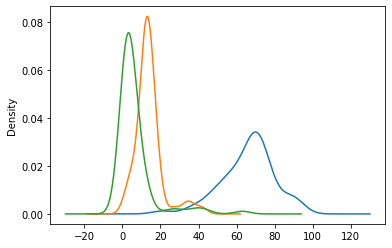

In [198]:
silica.plot.kde()
alumina.plot.kde()
cao.plot.kde()
# plt.xlim(0,100)

(array([2., 0., 9., 7., 8., 7., 5., 5., 9., 0., 1., 3.]),
 array([ 6.05 , 13.315, 20.58 , 27.845, 35.11 , 42.375, 49.64 , 56.905,
        64.17 , 71.435, 78.7  , 85.965, 93.23 ]),
 <BarContainer object of 12 artists>)

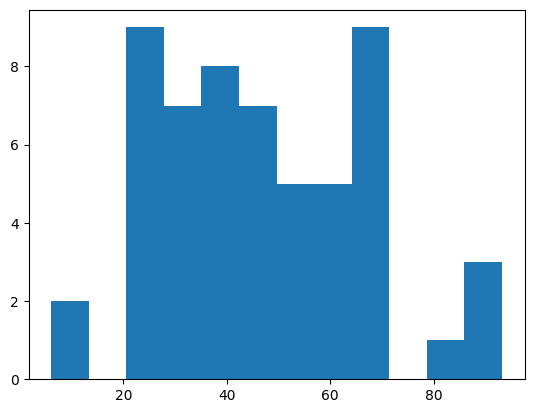

In [362]:
plt.hist(sio2_mol+sio2_wt, bins=12)#, density=True)


In [350]:
getstats(sio2_mol+sio2_wt)

mean =  46.96
std =  19.99
max =  93.23
min =  6.05


In [347]:
getstats(sio2_wt)

mean =  44.04
std =  18.86
max =  71.09
min =  6.05


In [110]:
for idx, l in enumerate(empt):
    if len(l[-1]) == 0:
        print(idx,l)
        pii = l[0]
        tid = l[1]
        print(alldata[pii][tid]['caption'])
        display(pd.DataFrame(alldata[pii][tid]['act_table']))
        # break

0 ['S0958946500000032', 0, []]
Chemical analysis of the Portland cement and the fly ash used in the concrete (wt%)


,0,1,2
0,,Cement,Fly ash
1,Insoluble residue,1.10,
2,Ignition loss,3.88,3.27
3,SiO2,19.23,53.62
4,Al2O3,6.89,28.15
5,CaO,60.69,1.97
6,MgO,3.15,1.06
7,SO3,1.67,0.32
8,Na2O,0.52,0.52
9,K2O,0.74,2.51


1 ['S0958946500000196', 0, []]
Chemical composition and physical properties of cements and mineral admixtures


,0,1,2,3,4
0,,Low C3S cement,High C3S cement,Natural pozzolana,Limestone filler
1,"Chemical composition, % in weight","Chemical composition, % in weight","Chemical composition, % in weight","Chemical composition, % in weight","Chemical composition, % in weight"
2,SiO2,23.66,21.00,76.9,10.63
3,Al2O3,3.00,3.29,9.8,1.20
4,Fe2O3,5.41,4.68,3.6,0.78
5,CaO,62.14,66.00,1.8,47.16
6,MgO,0.60,0.67,0.5,0.39
7,SO3,1.59,2.20,-,0.16
8,K2O,-,-,1.4,0.34
9,Na2O,-,-,3.7,-


2 ['S0958946500000196', 1, []]
Flexural strength, compressive strength and relative strength at selected ages after sulphate immersion


...

,0,1
0,SiO2 (%),20.4
1,Al2O3 (%),4.89
2,Fe2O3 (%),3.18
3,CaO (%),64.02
4,MgO (%),2.56
5,SO3 (%),2.85
6,Na2O (%),0.07
7,K2O (%),0.53
8,Insoluble residue (%),0.37
9,Loss on ignition (%),0.98


1746 ['S0958946599000347', 0, []]
Physical properties and main chemical compositions of cement and mineral admixtures


,0,1,2,3,4,5
0,,Unit,OPC,FA,BFS,SF
1,Physical properties,,,,,
2,Specific gravity,,3.17,2.18,2.91,2.16
3,Fineness (Blaine),cm2/g,3270,3240,8070,-
4,(BET),m2/g,-,-,-,20.2
5,Moisture content,%,-,0.13,-,0.62
6,,,,,,
7,Chemical composition,,,,,
8,L.O.I,%,0.6,1.74,0.4,3.64
9,SiO2,%,21.3,50.71,33.7,92.69


1747 ['S0958946599000396', 2, []]
Chemical and physical properties of the cementing material


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,Chemical properties,Chemical properties,Chemical properties,Chemical properties,Chemical properties,Chemical properties,Chemical properties,Chemical properties,Chemical properties,Chemical properties,Physical properties,Physical properties,Physical properties
1,SiO2,Fe2O3,Al2O3,CaO,MgO,SO3,Na2O,K2O,Loss on ignition,Soluble residue,Fineness (m2/kg),Setting time (initial - min),"s c,14d (MPa)"
2,20.70,3.00,4.61,64.70,1.00,3.00,0.13,0.65,1.30,0.38,353,135,59.20


In [216]:
'cement' in alldata[pii][tid]['caption']

True

In [201]:
if 'cement' in alldata[pii][tid]['caption'] or 'cement' in str(alldata[pii][tid]['act_table']).lower():
    print('here')

here


In [ ]:
resnew = [r for r in reslist if len(r) > 0]

In [50]:
ids = res['identifier']

In [51]:
tabeltype = res['pred_table_type_labels']

In [52]:
df = pd.DataFrame(ids)

In [53]:
df['table_type'] = tabeltype

In [54]:
df.columns = ['pii', 'table_id','table_type']

In [55]:
df.table_type.value_counts()

table_type
3    16332
1     1765
0      353
2      130
Name: count, dtype: int64

In [56]:
df.shape

(18580, 3)

In [57]:
# ccr - 18580
# ccc - 16952
# cbm - 151458

In [58]:
# 0 -> SCC, 1 -> MCC-CI, 2 -> MCC-PI, 3 -> NC

In [59]:
mapper_type = {0:'SCC',1:'MCC-CI',2:'MCC-PI',3:'NC'}

In [60]:
df['table_type_names'] = df['table_type'].apply(lambda x: mapper_type[x])

In [62]:
df.table_type_names.value_counts()

table_type_names
NC        16332
MCC-CI     1765
SCC         353
MCC-PI      130
Name: count, dtype: int64

In [77]:
mask = df.table_type_names == 'NC'
dfcomp = df[~mask]#.value_counts()

In [9]:
np.random.seed(0)
# dfcomp.sample(dfcomp.shape[0]).to_excel('ccr_compinfo.xlsx',index=False)

In [63]:
np.random.seed(0)
dfcheck = df.sample(30)

In [70]:
# dfcheck.to_csv('ccr_check.csv', index=False)

In [69]:
# "https://www.sciencedirect.com/science/article/pii/" + dfcheck.pii.values

In [23]:
np.random.seed(0)
random.seed(0)
# random.shuffle(ids)

In [11]:
np.random.seed(0)
random.seed(0)
random.shuffle(resnew)

In [ ]:
# S0008884604004855, missed 2 ; flyash and ggbs
# 

In [72]:
cements = [2,1,1,1,1,2,1,2,1,1,1,3,2,1,2]
binder = [5]
slag = [2,4,2]
csmix = [6]
flyash  = [4,1,2]
silicafume  = [1]
tailings = [2]
other = [2,1,1] 
# S0008884614002166

In [75]:
sum(cements), sum(binder), sum(slag), sum(csmix), sum(flyash), sum(silicafume),  sum(tailings), sum(other)

(22, 5, 8, 6, 7, 1, 2, 4)

In [19]:
resnew[7]

[('S0008884606001347_0_1_1_0_Cement 1', 'CaO', 62.4, 'mol'),
 ('S0008884606001347_0_1_1_0_Cement 1', 'SO3', 2.96, 'mol'),
 ('S0008884606001347_0_1_1_0_Cement 1', 'SiO2', 20.1, 'mol'),
 ('S0008884606001347_0_1_1_0_Cement 1', 'Al2O3', 4.9, 'mol'),
 ('S0008884606001347_0_1_1_0_Cement 1', 'Fe2O3', 2.34, 'mol'),
 ('S0008884606001347_0_1_1_0_Cement 1', 'Na2O', 0.21, 'mol'),
 ('S0008884606001347_0_1_1_0_Cement 1', 'K2O', 0.74, 'mol'),
 ('S0008884606001347_0_2_1_0_Cement 2', 'CaO', 67.2, 'mol'),
 ('S0008884606001347_0_2_1_0_Cement 2', 'SO3', 2.1, 'mol'),
 ('S0008884606001347_0_2_1_0_Cement 2', 'SiO2', 22.7, 'mol'),
 ('S0008884606001347_0_2_1_0_Cement 2', 'Al2O3', 2.9, 'mol'),
 ('S0008884606001347_0_2_1_0_Cement 2', 'MgO', 0.71, 'mol'),
 ('S0008884606001347_0_2_1_0_Cement 2', 'Fe2O3', 2.0, 'mol'),
 ('S0008884606001347_0_2_1_0_Cement 2', 'Na2O', 0.29, 'mol'),
 ('S0008884606001347_0_2_1_0_Cement 2', 'K2O', 0.1, 'mol')]

In [69]:
# resnew[16]
# resnew[21]

In [44]:
from tqdm import trange, tqdm

In [45]:
count = 0
for paper in tqdm(resnew):
    # paper = resnew[0]
    for r in paper:
        # print(r)
        matlist = []
        for rid in paper:
            mat = rid[0]
            idx = mat.split('_')[2]
            # print(rids)
            if idx not in matlist:
                matlist.append(idx)
        count+= len(matlist)


100%|██████████████████████████████████████████████████████████| 2043/2043 [00:01<00:00, 1513.07it/s]


In [11]:
wrong = [6,1,2,9,1,2,6,3]
right = [5,2]

In [12]:
2/10 correct

SyntaxError: invalid syntax (3745872038.py, line 1)

In [ ]:
wrong = [1,]
right = [4,6,2,6,8,10,]
grey = [4]

In [3]:
res = pickle.load(open('./Cement_and_Concrete_Composites/res_discomat_r1.pkl','rb'))

In [4]:
reslist = res['pred_tuples']

In [5]:
import random

In [6]:
import numpy as np

In [7]:
resnew = [r for r in reslist if len(r)>0]

In [8]:
len(resnew)

1796

In [44]:
2043+1796

3839

In [9]:
np.random.seed(0)
random.seed(0)
random.shuffle(resnew)

In [10]:
# S0008884604004855, missed 2 ; flyash and ggbs
# 

In [22]:
# cements = [2,1,1,1,1,2,1,2,1,1,1,3,2,1,2]
# binder = [5]
# slag = [2,4,2]
# csmix = [6]
# flyash  = [4,1,2]
# silicafume  = [1]
# tailings = [2]
# other = [2,1,1] 
# # S0008884614002166
cements = [1,1,1,1,1,1,1,1,1,1,1,2,1,1,2]
binder = [2]
slag = [8,1,1]
csmix =  []
flyash  =  [1,1,1,1,2,1]
silicafume  = [1,1,1,1]
tailings = []
other = [1,1,1,1]
# clinker, gypsum, limestone
clay = [1]


# 12 S0958946522001937_0_2_0_0



In [23]:
sum(cements), sum(binder), sum(slag), sum(csmix), sum(flyash), sum(silicafume),  sum(tailings), sum(other)

(17, 2, 10, 0, 7, 4, 0, 4)

In [21]:
resnew[21]

[('S0958946516306424_0_1_1_0_OPC', 'SiO2', 19.32, 'wt'),
 ('S0958946516306424_0_1_1_0_OPC', 'Al2O3', 4.38, 'wt'),
 ('S0958946516306424_0_1_1_0_OPC', 'Fe2O3', 3.17, 'wt'),
 ('S0958946516306424_0_1_1_0_OPC', 'CaO', 62.73, 'wt'),
 ('S0958946516306424_0_1_1_0_OPC', 'MgO', 2.63, 'wt'),
 ('S0958946516306424_0_1_1_0_OPC', 'SO3', 3.31, 'wt'),
 ('S0958946516306424_0_1_1_0_OPC', 'CaCO3', 3.21, 'wt'),
 ('S0958946516306424_0_1_2_0_CSA-based EX', 'SiO2', 8.22, 'wt'),
 ('S0958946516306424_0_1_2_0_CSA-based EX', 'Al2O3', 7.41, 'wt'),
 ('S0958946516306424_0_1_2_0_CSA-based EX', 'Fe2O3', 1.25, 'wt'),
 ('S0958946516306424_0_1_2_0_CSA-based EX', 'CaO', 53.21, 'wt'),
 ('S0958946516306424_0_1_2_0_CSA-based EX', 'MgO', 0.11, 'wt'),
 ('S0958946516306424_0_1_2_0_CSA-based EX', 'SO3', 28.23, 'wt')]

In [69]:
# resnew[16]
# resnew[21]

In [24]:
res = pickle.load(open('./Construction_and_Building_Materials/res_discomat_r1.pkl','rb'))

In [25]:
reslist = res['pred_tuples']

In [26]:
import random

In [27]:
import numpy as np

In [28]:
resnew = [r for r in reslist if len(r)>0]

In [29]:
len(resnew)

10287

In [45]:
3839 + 10287

14126

In [30]:
np.random.seed(0)
random.seed(0)
random.shuffle(resnew)

In [31]:
# S0008884604004855, missed 2 ; flyash and ggbs
# 

In [68]:
# cements = [2,1,1,1,1,2,1,2,1,1,1,3,2,1,2]
# binder = [5]
# slag = [2,4,2]
# csmix = [6]
# flyash  = [4,1,2]
# silicafume  = [1]
# tailings = [2]
# other = [2,1,1] 
# # S0008884614002166
cements = [1,1,1,1,1]
binder = []
slag = [1,1,1]
csmix =  []
flyash  =  [1,3,1]
silicafume  = [1,1]
tailings = [1,]
other = [1,1,1]
# clinker, gypsum, limestone
clay = [1]


# 12 S0958946522001937_0_2_0_0



In [69]:
sum(cements), sum(binder), sum(slag), sum(csmix), sum(flyash), sum(silicafume),  sum(tailings), sum(other)

(5, 0, 3, 0, 5, 2, 1, 3)

In [ ]:
(17, 2, 10, 0, 7, 4, 0, 4)
(22, 5, 8, 6, 7, 1, 2, 4)


In [70]:
cements = 5+17+22
binder = 7
slag = 3+10+8
flyash = 5+7+7
silicafume = 4+1+2
tailings = 3

others = 6+8+3

In [73]:
cements, binder, slag, flyash, silicafume, tailings, others

(44, 7, 21, 19, 7, 3, 17)

In [76]:
44+7+21+19+7+3+17

118

In [ ]:
labels = ['cement','binder','slag','flyash','silicafume','tailings','others']
counts = [44, 7, 21, 19, 7, 3, 17]

In [ ]:
50 tables
137 compositions


In [71]:
sum(cements), sum(binder), sum(slag), sum(csmix), sum(flyash), sum(silicafume),  sum(tailings), sum(other)

TypeError: 'int' object is not iterable

In [67]:
# resnew[26]

In [ ]:
1,3,6,9,10

In [78]:
from tqdm import tqdm

In [86]:
resnew[2]

[('S0950061821003317_2_2_1_0_97/7', 'Fe2O3', 3.0, 'mol'),
 ('S0950061821003317_2_2_1_0_97/7', 'Na2O', 13.0, 'mol'),
 ('S0950061821003317_2_2_1_0_97/7', 'MgO', 62.0, 'mol'),
 ('S0950061821003317_2_2_1_0_97/7', 'CaO', 4.0, 'mol'),
 ('S0950061821003317_2_2_1_0_97/7', 'Al2O3', 1.0, 'mol'),
 ('S0950061821003317_2_2_1_0_97/7', 'SiO2', 1.0, 'mol'),
 ('S0950061821003317_2_3_1_0_18/10', 'Fe2O3', 13.0, 'mol'),
 ('S0950061821003317_2_3_1_0_18/10', 'Na2O', 89.0, 'mol'),
 ('S0950061821003317_2_3_1_0_18/10', 'K2O', 45.0, 'mol'),
 ('S0950061821003317_2_3_1_0_18/10', 'MgO', 4.0, 'mol'),
 ('S0950061821003317_2_3_1_0_18/10', 'CaO', 9.0, 'mol'),
 ('S0950061821003317_2_3_1_0_18/10', 'Al2O3', 4.0, 'mol'),
 ('S0950061821003317_2_3_1_0_18/10', 'SiO2', 8.0, 'mol'),
 ('S0950061821003317_2_4_1_0_25/9', 'Fe2O3', 2.0, 'mol'),
 ('S0950061821003317_2_4_1_0_25/9', 'Na2O', 44.0, 'mol'),
 ('S0950061821003317_2_4_1_0_25/9', 'MgO', 63.0, 'mol'),
 ('S0950061821003317_2_4_1_0_25/9', 'CaO', 8.0, 'mol'),
 ('S095006182100331

In [87]:
count = 0
for paper in tqdm(resnew):
    # paper = resnew[0]
    for r in paper:
        # print(r)
        matlist = []
        for rid in paper:
            mat = rid[0]
            idx = mat.split('_')[-1]
            # print(rids)
            if idx not in matlist:
                matlist.append(idx)
        count+= len(matlist)


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10287/10287 [00:04<00:00, 2308.13it/s]


In [88]:
count

818417

In [6]:
dfs = pd.read_csv('cement_all_comps.csv')

In [7]:
dfs

,CaO,SiO2,CaO_1,Fe2O3,Al2O3,MgO,Na2O,K2O,mid,SO3,...,Ti_3,Fe_3,K2O_3,Ba(OH)2,WC,F3_2,Cr2O2,SS,Br2O,CrO5
0,4.60,48.80,0.25,7.40,26.80,1.90,0.67,3.60,S0008884600001988_0_1_3_0_FA-A,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6.70,45.20,0.14,9.10,25.30,1.70,0.48,3.20,S0008884600001988_0_2_3_0_FA-B,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,49.30,26.80,1.20,3.60,14.70,1.30,0.30,1.10,S0008884600001988_0_3_3_0_FABC-A,0.60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,47.40,26.70,1.00,4.60,16.40,1.30,0.20,0.98,S0008884600001988_0_4_3_0_FABC-B,0.60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,63.92,21.17,NaN,2.28,5.34,3.91,0.47,NaN,S0008884600002003_1_1_1_0_Type I cement,2.32,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40449,31.38,0.36,NaN,0.16,0.16,20.98,NaN,NaN,S0958946599000220_0_2_1_0_Dolomite (NM-0),NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40450,64.02,20.40,NaN,3.18,4.89,2.56,0.07,0.53,S0958946599000311_1_0_1_0,2.85,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40451,64.40,21.30,NaN,NaN,5.30,2.20,0.20,0.60,S0958946599000347_0_9_2_0_OPC,1.90,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40452,41.90,33.70,NaN,NaN,13.40,7.10,0.20,0.30,S0958946599000347_0_9_4_0_BFS,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<h2> real analysis


In [9]:
def nzcols(dk):
    mk = dk.astype(bool).sum(axis=0)
    return dk.T[mk.astype(bool)].T

In [10]:
dfs  = pd.read_csv('cement_all_comps.csv')

In [65]:
# dfs.shape

In [20]:
colist = dfs.columns.to_list()

In [21]:
colist.remove('mid')

In [22]:
colist = colist + ['mid']

In [23]:
dfs = dfs[colist].fillna(0)

In [24]:
word_dict = dict()
for word in ['calcined clay','pumice','clay', 'ash','slag','tail','husk','kaolin','stone','ggbs','fume', 'clinker', 'cement','opc','pozzol','filler','scm']:
    word_dict[word] = 0

In [25]:
# 'na' in
# for nn in dfs.columns.tolist():
#     nn = nn.lower()
#     # if 'Na' in nn:
#         print(nn)

In [66]:
# dfs[dfs.mid.apply(lambda x: 'calcined clay' in str(x).lower())].drop_duplicates(subset=['SiO2','CaO','Fe2O3','Al2O3','MgO','Na2O','K2O'])

In [ ]:
sum(dfs[colist[:-1]].sum(axis=1).between(90,102))

24427

In [32]:
import matplotlib.pyplot as plt

In [33]:
# >200          245
# 100 - 200    4181
# 90 - 100    22676
# 80 - 90     2639
# 50 - 80     2776
# 10 - 50      1408
# 2 - 10   888
# 1 - 1.2  5935
# 0.8 - 1  5838
# 0 - 0.8  344

In [67]:
ranges = [[200, 2000000], [100,200], [90,100], [80,90], [50,80],[10,50],[2,10],[1, 1.2], [0.8,1], [0, 0.8]]

In [68]:
np.random.seed(0)
dfss = dfs.sample(300)

In [69]:
dfss['pii'] = dfss.mid.apply(lambda x: x.split('_'))

In [62]:
total = 0
pii_tids = []
dfcheck = pd.DataFrame()
nums2 = []
sumlabel = []
for rnid, r in enumerate(ranges):
    mask = (dfss[colist[:-1]].sum(axis=1)).between(r[0], r[1])
    checknum = sum(mask)
    total += checknum
    print(r, 1*checknum/total)#/dfs.shape[0])
    dfshow = nzcols(dfss[mask])
    ana
    pii_tids.extend(list(dfshow.pii.values))
    sumlabel.extend(checknum*[r])
    dfcheck = pd.concat((dfcheck, dfshow))
    # display(dfshow)
    nums2.append(checknum)

[200, 2000000] 1.0
[100, 200] 0.8709677419354839
[90, 100] 0.8385416666666666
[80, 90] 0.12727272727272726
[50, 80] 0.07172995780590717
[10, 50] 0.04048582995951417
[2, 10] 0.01984126984126984
[1, 1.2] 0.15436241610738255
[0.8, 1] 0.13119533527696792
[0, 0.8] 0.008670520231213872


(346, 96)

In [54]:
sumlab = dfss[colist[:-1]].sum(axis=1)

In [56]:
dfss['summ'] = sumlab

In [58]:
# dfss

In [70]:
analyse = []
for p in pii_tids:
    pii = p[0]
    tid = p[1]
    ptid = f'{pii}_{tid}'
    if ptid not in analyse:
        analyse.append(ptid)
    

In [77]:
dfss['pii_tid'] = dfss.mid.apply(lambda x: '_'.join(x.split('_')[:2]))
dfs['pii_tid'] = dfs.mid.apply(lambda x: '_'.join(x.split('_')[:2]))

In [80]:
unique_pii_tids = dfss.pii_tid.values

In [72]:
len(pii_tids)

346

In [79]:
pii_tid

['S0950061816308480', '0', '3', '0', '0']

In [86]:
sum_dict= dict()
for pii_tid in unique_pii_tids:
    tempdf = dfs[dfs.pii_tid == pii_tid]
    sum_dict[pii_tid] =  tempdf[colist[:-1]].sum(axis=1).median()
    # break
    

In [88]:
with open('sumdict.pkl','wb') as f:
    pickle.dump(sum_dict, f)
f.close()

In [89]:
pwd

'/home/civil/phd/cez198233/users/Tanishq/DiSCoMaT/code_and_data/code/inference/bigdata'

In [71]:
len(analyse)

296

In [27]:
# np.unique(analyse)

In [28]:
analyse[0]

'S0950061816308480_0'

In [29]:
# pd.Series(analyse).to_csv('analyse_tables.csv',index=False)

In [95]:
STRR = 'S0008884621003355_2'
# S0008884621003215_1
pii = STRR.split('_')[0]
idx = STRR.split('_')[-1]

for p in alldata_dicts:
    try:
        print(p[pii][int(idx)]['caption'])
        
        print(p[pii][int(idx)]['act_table'])
        display(pd.DataFrame(p[pii][int(idx)]['act_table']))
    except Exception as e:
        print(e)
        pass

Formulations studied.
[['Mixture', 'C3S (wt%)', 'Gypsum (wt%)', 'Test conducted'], ['C3S', '100.00', '0.00', 'IC, TGA, XRD, 29Si NMR'], ['C3S_2.5%G', '97.56', '2.44', 'IC, TGA, XRD, 29Si NMR'], ['C3S_5.0%G', '95.24', '4.76', 'IC'], ['Al-C3S', '100.00', '0.00', 'IC, TGA, XRD, 29Si NMR, 27Al NMR'], ['Al-C3S _2.5%G', '97.56', '2.44', 'IC, TGA, XRD, 29Si NMR, 27Al NMR'], ['Al-C3S _5.0%G', '95.24', '4.76', 'IC']]


,0,1,2,3
0,Mixture,C3S (wt%),Gypsum (wt%),Test conducted
1,C3S,100.00,0.00,"IC, TGA, XRD, 29Si NMR"
2,C3S_2.5%G,97.56,2.44,"IC, TGA, XRD, 29Si NMR"
3,C3S_5.0%G,95.24,4.76,IC
4,Al-C3S,100.00,0.00,"IC, TGA, XRD, 29Si NMR, 27Al NMR"
5,Al-C3S _2.5%G,97.56,2.44,"IC, TGA, XRD, 29Si NMR, 27Al NMR"
6,Al-C3S _5.0%G,95.24,4.76,IC


'S0008884621003355'
'S0008884621003355'


In [92]:
print(p[pii][int(idx)]['act_table'])

TypeError: tuple indices must be integers or slices, not str

In [91]:
for ex in extracted:
    for p in ex:
        if p[0].startswith(STRR):
            print(p)

('S0008884621003355_2_0_1_0', 'C', 0.75, 'wt')
('S0008884621003355_2_0_1_0', 'S', 0.25, 'wt')
('S0008884621003355_2_1_0_0', 'C', 0.75, 'mol')
('S0008884621003355_2_1_0_0', 'S', 0.25, 'mol')
('S0008884621003355_2_4_0_0', 'Al', 0.2, 'mol')
('S0008884621003355_2_4_0_0', 'C', 0.6, 'mol')
('S0008884621003355_2_4_0_0', 'S', 0.2, 'mol')
('S0008884621003355_2_5_0_0', 'Al', 0.2, 'mol')
('S0008884621003355_2_5_0_0', 'C', 0.6, 'mol')
('S0008884621003355_2_5_0_0', 'S', 0.2, 'mol')
('S0008884621003355_2_6_0_0', 'Al', 0.2, 'mol')
('S0008884621003355_2_6_0_0', 'C', 0.6, 'mol')
('S0008884621003355_2_6_0_0', 'S', 0.2, 'mol')


In [51]:
dfcheck.drop_duplicates(dfss.columns.tolist()[:-2]).shape

KeyError: Index(['F2_1', 'K2O5', 'P2O5_2', 'As2O3_1', 'SnO2', 'Fe4O3', 'K2O_3', 'PF950',
       'Na2SO4_1', 'P_2',
       ...
       'Fe2O4', 'Co3O4_1', 'Nd2O3_1', 'Na2SiF6', 'Na20', 'Al2O2', 'Nd2O3',
       'F2_5', 'Na2', 'PFN4'],
      dtype='object', length=391)

In [64]:
mk

CaO      1
SiO2     1
CaO_1    0
Fe2O3    1
Al2O3    1
        ..
Cr2O2    0
SS       0
Br2O     0
CrO5     0
mid      3
Length: 485, dtype: int64

In [42]:
sums = dfs[colist[:-1]].sum(axis=1)
mask = sums.between([0,0.8])
print(len(sums), sum(mask))
plt.hist(sums[mask])

TypeError: between() missing 1 required positional argument: 'right'

In [41]:
dfs.drop_duplicates(subset=['CaO','SiO2','Fe2O3','Al2O3','MgO','Na2O','K2O','SO3','TiO','Mn2O3','PbO']).shape

(26636, 485)

In [65]:
dfs['mid'].apply(lambda x: 'metakaolin' in str(x).lower()).sum()

131